# Stereo matching with intra- and inter-scanline dynamic programming

From-scratch implementation of a dense stereo method inspired by **Ohta & Kanade (1985)**, *Stereo by Intra- and Inter-Scanline Search Using Dynamic Programming*.

For each row of a rectified stereo pair we search, on a graph of `(column, disparity)` nodes, the path with the lowest total cost. The cost of a path is the photometric matching cost plus penalties for disparity changes **along the row** (intra-scanline) and **with respect to the row above** (inter-scanline).

The implementation lives in the `stereo_dp` package; this notebook walks through each step.

In [1]:
import sys
sys.path.append("..")  # make the stereo_dp package importable from notebooks/

import cv2
import numpy as np
import matplotlib.pyplot as plt

from stereo_dp import matching_cost, inter_scanline_penalty, aggregate_scanline, backtrack, disparity_dp
from stereo_dp.visualization import show_epipolar_lines, compare_disparity_maps, plot_disparity_surface

## 1. Load the images and check the rectification

The method assumes a **rectified** pair: a point of the scene appears on the same row in both images, so the search for its match is one-dimensional. Drawing horizontal lines over both images is a quick visual check.

(375, 450) (375, 450)


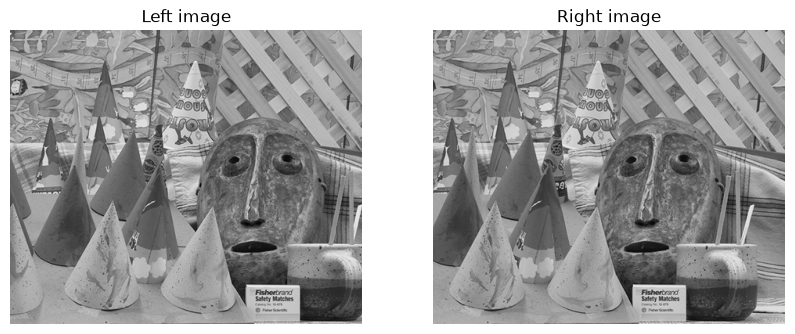

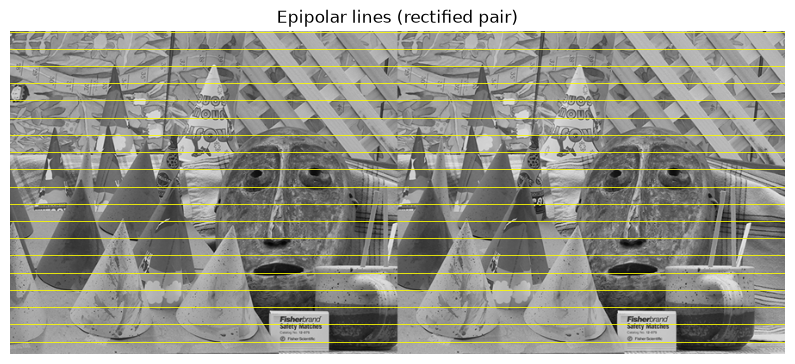

In [2]:
img_left = cv2.imread("../images/cones_left.png", cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread("../images/cones_right.png", cv2.IMREAD_GRAYSCALE)
print(img_left.shape, img_right.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img_left, cmap="gray"); ax[0].set_title("Left image"); ax[0].axis("off")
ax[1].imshow(img_right, cmap="gray"); ax[1].set_title("Right image"); ax[1].axis("off")
plt.show()

show_epipolar_lines(img_left, img_right)
plt.show()

## 2. Matching cost

For a row `y`, pixel `x` of the left image is compared with pixel `x - d` of the right image for every disparity `d`:

$$\text{cost}(x, d) = |I_L(x, y) - I_R(x - d, y)|$$

When `x - d` falls outside the image the pixel cannot be matched, and it receives a fixed **occlusion cost**. The result is a `(width, max_disparity)` table — the nodes of the graph for that row.

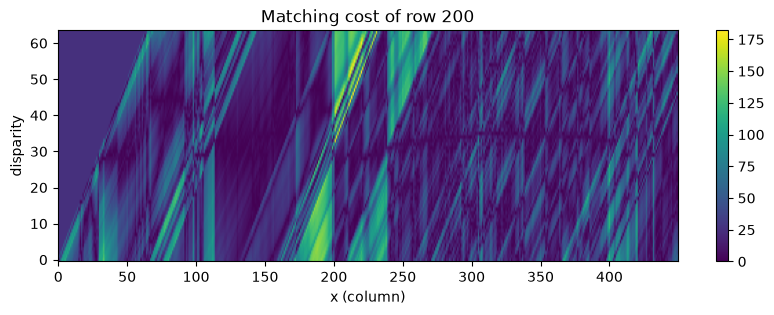

In [3]:
max_disparity = 64
occlusion_cost = 25
y = 200

cost = matching_cost(img_left[y], img_right[y], max_disparity, occlusion_cost)

plt.figure(figsize=(10, 3))
plt.imshow(cost.T, aspect="auto", cmap="viridis", origin="lower")
plt.xlabel("x (column)"); plt.ylabel("disparity"); plt.title(f"Matching cost of row {y}")
plt.colorbar(); plt.show()

## 3. Intra-scanline search (dynamic programming)

The best disparity profile of the row is the cheapest path from the left edge to the right edge of the cost table. Between neighbouring columns the path may keep its disparity or move by one level, paying a penalty $P_h$:

$$C(x, d) = \text{cost}(x, d) + \min\big(C(x-1, d),\; C(x-1, d-1) + P_h,\; C(x-1, d+1) + P_h\big)$$

The forward pass fills the accumulated cost $C$ and stores where each node came from; backtracking from the cheapest node of the last column recovers the path.

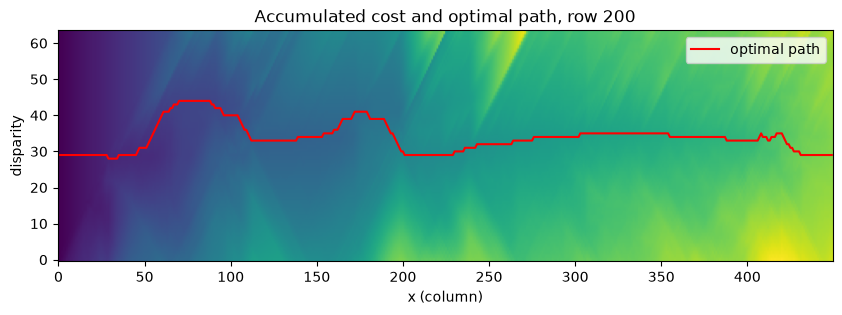

In [4]:
P_h = 25
accumulated, back = aggregate_scanline(cost, P_h)
path = backtrack(accumulated, back)

plt.figure(figsize=(10, 3))
plt.imshow(accumulated.T, aspect="auto", cmap="viridis", origin="lower")
plt.plot(path, color="red", linewidth=1.5, label="optimal path")
plt.xlabel("x (column)"); plt.ylabel("disparity"); plt.title(f"Accumulated cost and optimal path, row {y}")
plt.legend(); plt.show()

## 4. Inter-scanline consistency

Solving every row independently produces horizontal streaks, because nothing ties a row to its neighbours. Following the idea of Ohta & Kanade, the disparity chosen on the row above is used as a prior: every disparity different from it costs an extra $P_v$ before the DP runs on the current row.

In [5]:
P_v = 3
previous_row = disparity_dp(img_left[y - 1:y], img_right[y - 1:y], max_disparity, P_h, 0, occlusion_cost)[0]
cost_with_prior = inter_scanline_penalty(cost, previous_row, P_v)
print("penalised entries per column:", int((cost_with_prior != cost).sum() / cost.shape[0]))

penalised entries per column: 63


## 5. Full disparity map

`disparity_dp` repeats the steps above for every row. With `p_vertical=0` it is plain row-by-row DP.

In [6]:
%%time
disparity_rows = disparity_dp(img_left, img_right, max_disparity, P_h, p_vertical=0, occlusion_cost=occlusion_cost)
disparity = disparity_dp(img_left, img_right, max_disparity, P_h, p_vertical=P_v, occlusion_cost=occlusion_cost)

CPU times: user 3.27 s, sys: 1.06 ms, total: 3.27 s
Wall time: 3.3 s


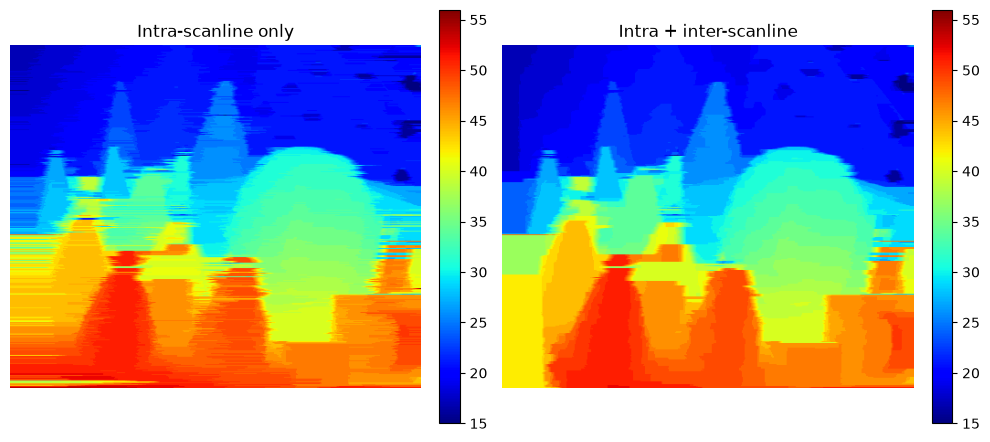

In [7]:
compare_disparity_maps({
    "Intra-scanline only": disparity_rows,
    "Intra + inter-scanline": disparity,
})
plt.show()

The inter-scanline term removes most of the streaks and gives coherent regions for each object, at no extra cost in run time.

## 6. 3D view

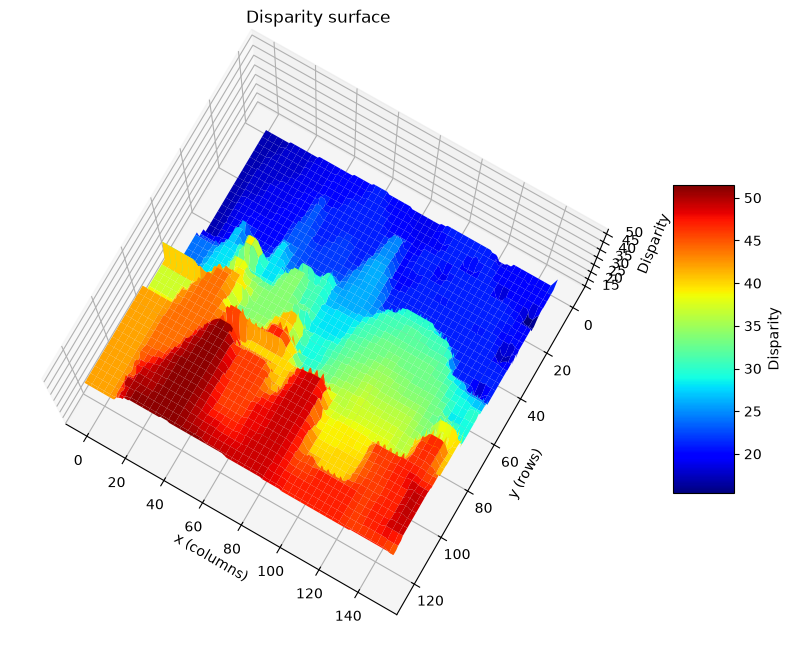

In [8]:
plot_disparity_surface(disparity)
plt.show()

## 7. Effect of the parameters

* **`P_h`** — higher values give smoother rows but round off small objects.
* **`P_v`** — higher values propagate the disparity of the row above more strongly; too high and errors propagate downwards.
* **`occlusion_cost`** — controls how readily a pixel near the left border is treated as unmatched.

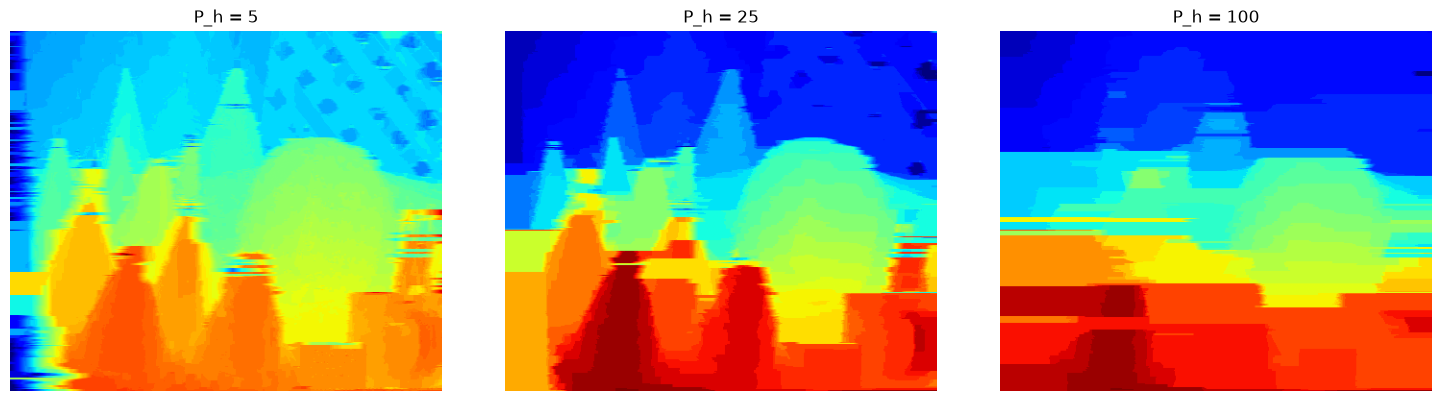

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ph in zip(axes, [5, 25, 100]):
    d = disparity_dp(img_left, img_right, max_disparity, ph, P_v, occlusion_cost)
    ax.imshow(d, cmap="jet"); ax.set_title(f"P_h = {ph}"); ax.axis("off")
plt.tight_layout(); plt.show()